# Notebook for analysis of bulk RNAseq data in BULLKpy
@mmm, November 2, 2026

<div style="font-size: 24px; line-height: 1.1">
Notebook Menu

<div style="font-size: 18px; line-height: 1.4">
<a href="#imports">1. Imports and settings</a><br>
<a href="#loads">2. Load original data into AnnData and BULLKpy object</a><br>
<a href="#pp">3. Quality control and Preprocessing</a><br>
<a href="#pca">4. PCA and Bidimensional Representation</a><br>
<a href="#utilities">5. Utilities</a><br>

# 1. Imports and settings
<a id="imports"></a>

## 1.1. Modules and Settings

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import anndata as ad
import bullkpy as bk

In [2]:
import sys
sys.version
print("Python:", sys.version, "Numpy:", np.__version__, "Pandas:", pd.__version__, "Matplotlib:", mpl.__version__, "Seaborn:", sns.__version__, 
      "AnnData:", ad.__version__)

Python: 3.12.13 (main, May 10 2026, 19:20:41) [Clang 22.1.3 ] Numpy: 2.4.6 Pandas: 3.0.5 Matplotlib: 3.11.1 Seaborn: 0.13.2 AnnData: 0.13.2


In [3]:
bk.settings.verbosity = 3
bk.settings.plot_theme = "paper"      # "default" | "paper" | "talk"
bk.settings.plot_palette = "Set1"
bk.settings.plot_fontsize = 10        # optional
bk.settings.plot_dpi = 200
bk.settings.save_dpi = 300

# every plot calls set_style() internally, or you can call once:
bk.pl.set_style()
pal = sns.color_palette("husl", n_colors=35)       # palette for large categories
bk.settings.set_palette_for("Project_ID", where="obs", palette="husl")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="lifelines")

Change to paths with your files:

In [4]:
# Generate your own structure of folders and adapt these paths to your own copies of the public source data.

DATA = "../data/"
DATA_EXTERNAL = "../data/external/"
DATA_H5AD = '../data/h5ad/'

RESULTS = "../results/"
FIGURES = "../results/figs/"
TABLES = "../results/tables/"
GSEA = "../results/gsea/"

import os
for _p in (DATA, DATA_EXTERNAL):
    if not os.path.isdir(_p):
        print(f"WARNING: {_p} not found - update DATA above before running section 2.")

# Single source of truth for the objects this notebook builds, so every save and
# reload below refers to the same file.

H5AD      = DATA_H5AD + "TCGA_lung.h5ad"

# 2. Load data into AnnData and BULLKpy object
<a id="loads"></a>

Find details and additional parameters for all functions in:  
- https://bullkpy.readthedocs.io/en/latest/api/index.html  

## 2.1. Load expression data and generate the AnnData/BULLKpy object

TCGA data is available here:
- https://portal.gdc.cancer.gov/
- https://xenabrowser.net/datapages/

The expression matrix below is the GDC Pan-Cancer (PANCAN) HTSeq table from UCSC
Xena. It is a large public download and is **not** distributed with BULLKpy:

- https://gdc-hub.s3.us-east-1.amazonaws.com/download/GDC-PANCAN.htseq_counts.tsv.gz

> **Important — this file is not raw counts.** Despite the `htseq_counts` name,
> Xena distributes it as **log2(count + 1)**. Feeding it straight into a counts
> workflow would treat log values as counts, so we back-transform to counts
> immediately after loading. `bk.io.read_counts` refuses to cast non-integer input
> to `int64` and warns, rather than silently truncating 10.77 to 10.

In [5]:
# TCGA subset of lung cancer samples, with gene expression counts and metadata from GDC.
LUNG = DATA_EXTERNAL + "lung/"

# this table was recovered from Xena's log₂(count+1) table
adata = bk.io.read_counts(LUNG + "TCGA_lung_counts.tsv.gz", sep="\t",
                          orientation="genes_by_samples")

# If necessary load the gene annotation table to map Ensembl IDs to gene symbols. 
genes = pd.read_csv(LUNG + "TCGA_lung_genes.tsv", sep="\t", index_col="ensembl_id")
adata.var = adata.var.join(genes)
adata.var["ensembl_id"] = adata.var_names.values
adata.var_names = adata.var["gene_name"].fillna(adata.var["ensembl_id"]).astype(str).values
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 1108 × 58272
    var: 'chromosome', 'gene_name', 'gene_type', 'ensembl_id'
    layers: None (.X)

### Check Genes

In [6]:
adata.var.head(3)

,chromosome,gene_name,gene_type,ensembl_id
TSPAN6,X,TSPAN6,protein_coding,ENSG00000000003.13
TNMD,X,TNMD,protein_coding,ENSG00000000005.5
DPM1,20,DPM1,protein_coding,ENSG00000000419.11


### Check Observations (Samples)

Check samples or metadata (if any)

In [7]:
adata.obs.head(5)

""
TCGA-97-7938-01A
TCGA-55-7574-01A
TCGA-05-4250-01A
TCGA-55-6979-11A
TCGA-95-A4VK-01A


Check expresion data

In [8]:
adata.X

array([[    2032,       15,     1220, ...,  3870124,  1301667, 12120738],
       [    1000,        0,      744, ...,  3593763,  1316191, 12615017],
       [    5355,        5,     2898, ...,  2304594,  2818442, 18783312],
       ...,
       [    2215,        0,     2618, ...,  4024490,  1635685, 16180185],
       [    2144,        1,     1262, ...,  3888963,  2651147, 34800303],
       [    2131,        8,     1218, ...,  3638487,  2140659, 22411669]],
      shape=(1108, 58272))

You can also use pandas or other python tools to read external data (counts, cpm, log-data etc.).  
See "Other tools" section at the end of the notebook.

## 2.2. Update metadata

Metadata store information relative to observations (Samples); e.g. tumor type; age of the patients, tumor purity, immune infiltration, survival, etc.  (see original BULLKpy publication for details)
Edit all your available data in an external table (excel, csv, tsv etc.)  
The "index_col" has be be identical to the listing of adata.obs above.

In [9]:
all_metadata = LUNG + "TCGA_lung_metadata.tsv"

In [10]:
# Option 1 for easy metadata tables
adata = bk.add_metadata(adata, all_metadata, 
                        low_memory=False, 
                        sep="\t",
                        index_col="sample",)
adata

AnnData object with n_obs × n_vars = 1108 × 58272
    obs: 'Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'initial_pathologic_dx_year', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'new_tumor_event_type', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Integrative', 'Subtype_Selected', 'sample_type_id', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'ICS5_score', 'LIexpression_score', 'Chemokine12_score', 'NHI_5gene_score', 'CD68', 'CD8A', 'PD1_data', 'PDL1_data', 'PD1_PDL1_score', 'CTLA4_data', 'Bcell_mg_IGJ', 'Bcell_receptors_score', 'STAT1_score', 'CSF1_response', 'TcClassII_score', 'IL12_score_21050467', 'IL4_score_21050467', 'IL2_score_21050467', 'IL13_score_21050467', 'IFNG_score_21050467', 'TGFB_score_21050467', 'TREM1_dat

In [11]:
# Modification of metadata; e.g. definition of tumor type
adata.obs["Sample_type"] = adata.obs_names.str[13:15].map(
    {"01": "Primary", "02": "Recurrent", "11": "Normal"}
)
adata.obs["Sample_type"].value_counts()


Sample_type
Primary      1000
Normal        106
Recurrent       2
Name: count, dtype: int64

In [12]:
#Complete table of metadata for the first 3 samples:
adata.obs.head(3)

,Sample_ID,Patient_ID,Project_ID,gender,race,ajcc_pathologic_tumor_stage,histological_type,initial_pathologic_dx_year,birth_days_to,vital_status,...,SLIT2_mut,MYC_mut,MYCL_mut,MYCN_mut,SOX2_mut,ASCL1_mut,NEUROD1_mut,POU2F3_mut,YAP1_mut,Sample_type
TCGA-97-7938-01A,TCGA-97-7938-01,TCGA-97-7938,LUAD,FEMALE,WHITE,Stage IA,Lung Adenocarcinoma,2011.0,-27980.0,Dead,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Primary
TCGA-55-7574-01A,TCGA-55-7574-01,TCGA-55-7574,LUAD,FEMALE,WHITE,Stage IB,Lung Adenocarcinoma,2011.0,-23703.0,Dead,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Primary
TCGA-05-4250-01A,TCGA-05-4250-01,TCGA-05-4250,LUAD,FEMALE,NaN,Stage IIIA,Lung Adenocarcinoma,2007.0,-29068.0,Dead,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Primary


## 2.3. Save AnnData object

In [14]:
# Save current objects to a single HDF5 file for later use. This is the main output of this notebook.
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")


If you find problems writing to .h5ad or with the format of the columns go to the last section (Other Tools) in this notebook

# 3. Quality Control and preprocessing
<a id="pp"></a>

If you are not sure about the format of the expression data:

In [15]:
# Integer (counts) or log transformed?
print("Are expression data integers: counts?")
X = adata.layers["counts"] if "counts" in adata.layers else adata.X
bk.pp._is_integerish(X)

Are expression data integers: counts?


True

In [16]:
# If counts, Save counts in a separata layer before normalization and log
### SKIP if data are already log-transformed
bk.pp.set_raw_counts(adata)      # layers["counts"]

## 3.1. Compute QC

If counts:  
- `bk.pp.qc_metrics(adata, layer="counts")`  

If log data:  
- `bk.pp.qc_metrics(adata, layer="log1p_cpm", detection_threshold=0.1)`  
will compute only n_genes_detected and warn about skipping count-based metrics

In [17]:
bk.pp.qc_metrics(adata, layer="counts", detection_threshold=5,
                mt_prefix='MT-',
                )
# will compute only n_genes_detected and warn about skipping count-based metrics

## 3.2. Visual QC overview

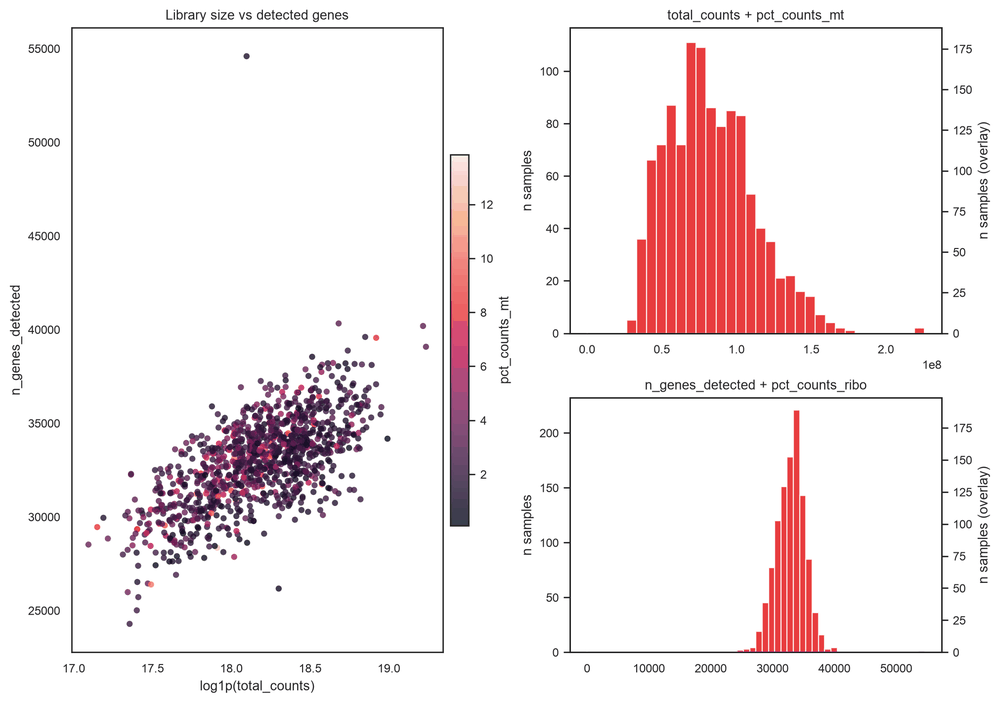

In [18]:
#If you only computed n_genes_detected
bk.pl.qc_metrics(
    adata,
    #color="n_genes_detected",
    #vars_to_plot="n_genes_detected",
    save=FIGURES + "qc_metrics_example.png",
);

### Filter out poor quality samples or genes

In [19]:
adata.obs[["n_genes_detected"]].describe()    #"total_counts", "pct_counts_mt"

,n_genes_detected
count,1108.000000
mean,32946.923285
std,2386.526292
min,24286.000000
25%,31393.000000
50%,33112.000000
75%,34431.750000
max,54591.000000


Filter out poor samples or genes
- If counts: use `layer="counts"`
- If normalized, `use layer="cpm"`
- If log-transformed, use `layer="log1p_cpm"`

In [20]:
# keep genes expressed in a minumum of X samples and with expression above a thershol
adata = bk.pp.filter_genes(adata, layer="counts", min_samples=20, min_expr=10)

In [21]:
# keep samples with a minimum of genes detected and minimum expression per gene
adata = bk.pp.filter_samples(adata, layer="counts", min_genes=15000, expr_threshold_for_genes=10)

In [22]:
# 4) Recompute QC after gene filtering (optional but nice)
bk.pp.qc_metrics(adata, layer="counts", detection_threshold=10)

### Normalize (skip is already normalized)

In [23]:
bk.pp.normalize_cpm(adata)                  # layers["cpm"]

### Log-transform (skip is already normalized and log-transformed)

In [24]:
bk.pp.log1p(adata)                          # layers["log1p_cpm"]

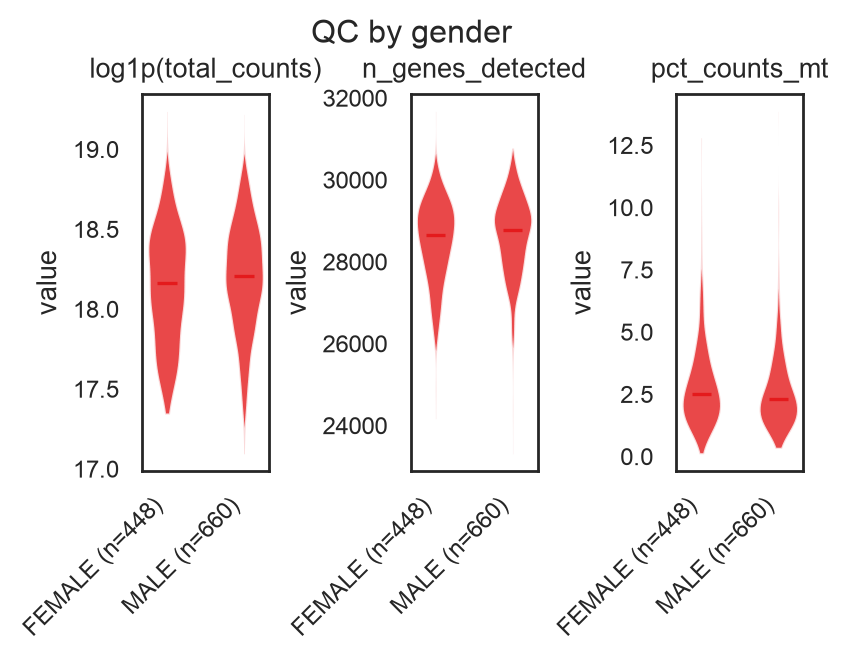

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: title={'center': 'log1p(total_counts)'}, ylabel='value'>,
        <Axes: title={'center': 'n_genes_detected'}, ylabel='value'>,
        <Axes: title={'center': 'pct_counts_mt'}, ylabel='value'>],
       dtype=object))

In [25]:
bk.pl.qc_by_group(adata, groupby="gender",
                  keys=('total_counts', 'n_genes_detected', 'pct_counts_mt'),
                  figsize=(4,3),
                  save=FIGURES + "qc_by_group_example.png",
                 )

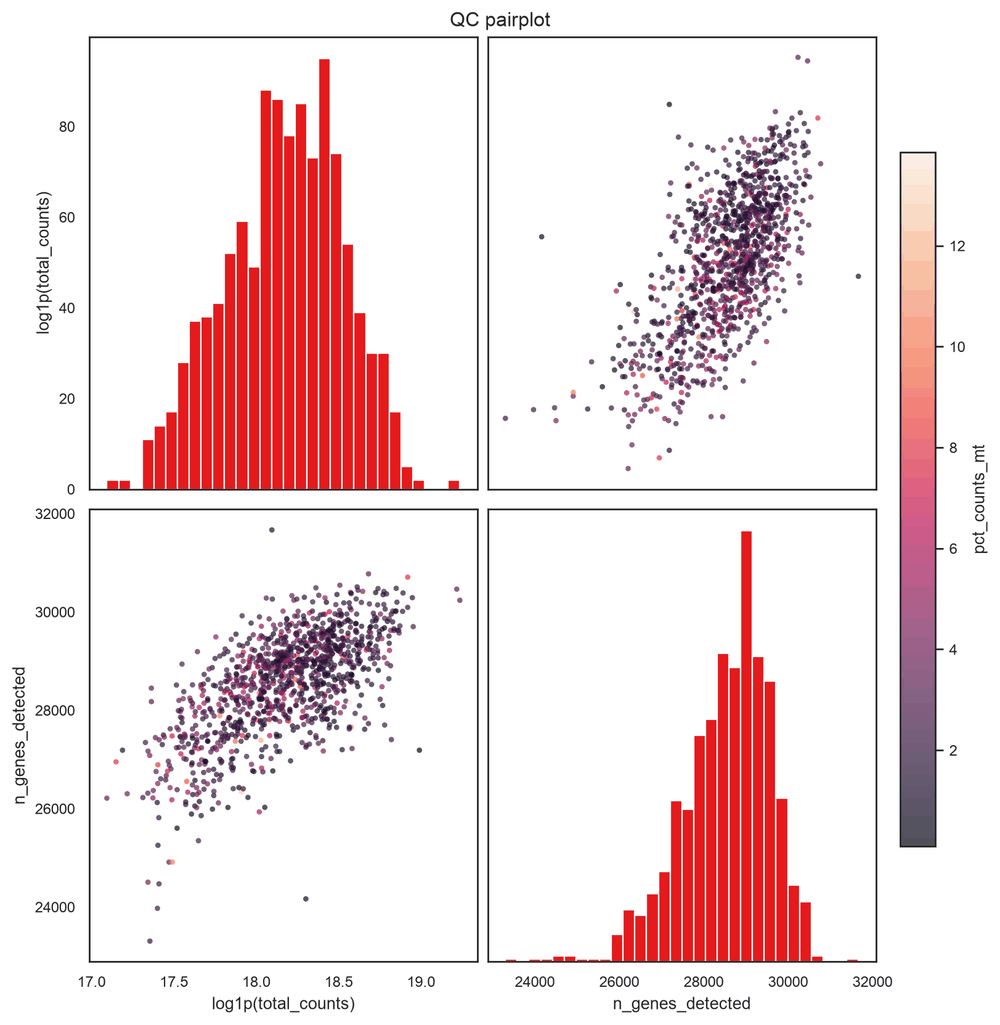

(<Figure size 1600x1600 with 5 Axes>,
 array([[<Axes: ylabel='log1p(total_counts)'>, <Axes: >],
        [<Axes: xlabel='log1p(total_counts)', ylabel='n_genes_detected'>,
         <Axes: xlabel='n_genes_detected'>]], dtype=object))

In [26]:
bk.pl.qc_pairplot(adata, keys=('total_counts', 'n_genes_detected', ),
                  save=FIGURES + "qc_pairplot_example.png",
                  point_size=10,
                 )

#'pct_counts_mt',

Store modified AnnData object with metrics

In [27]:
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")

# 4. PCA and bidimensional representation
<a id="pca"></a>

In [28]:
# Open .h5ad file if previously stored and not in memory
# skip if you come from previoys cells above and have adata in memory already
if 'adata' not in locals():
    adata = ad.read_h5ad(H5AD)
adata

AnnData object with n_obs × n_vars = 1108 × 31891
    obs: 'Sample_ID', 'Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'initial_pathologic_dx_year', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'new_tumor_event_type', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Integrative', 'Subtype_Selected', 'sample_type_id', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'ICS5_score', 'LIexpression_score', 'Chemokine12_score', 'NHI_5gene_score', 'CD68', 'CD8A', 'PD1_data', 'PDL1_data', 'PD1_PDL1_score', 'CTLA4_data', 'Bcell_mg_IGJ', 'Bcell_receptors_score', 'STAT1_score', 'CSF1_response', 'TcClassII_score', 'IL12_score_21050467', 'IL4_score_21050467', 'IL2_score_21050467', 'IL13_score_21050467', 'IFNG_score_21050467', 'TGFB_score_21050467', 'TREM1_dat

<Axes: xlabel='Project_ID'>

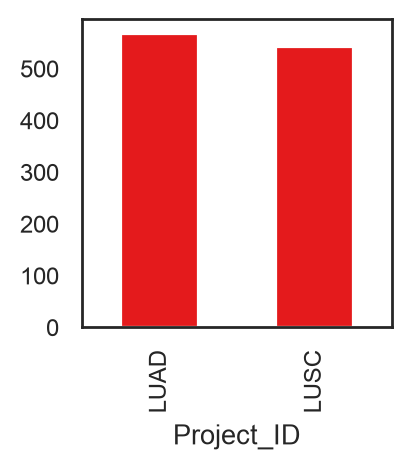

In [29]:
fig, ax = plt.subplots(figsize=(2,2), dpi=200)
adata.obs["Project_ID"].value_counts().plot(kind="bar")

## 4.1. Highly-variable genes & PCA

In [30]:
bk.pp.highly_variable_genes(adata, layer="log1p_cpm", n_top_genes=2000)
adata.var["highly_variable"].sum()

np.int64(2000)

If you ever see HVGs dominated by:
	•	mitochondrial genes
	•	ribosomal genes

you may want to exclude them before HVG selection:

- `mask = ~adata.var_names.str.startswith(("MT-", "RPS", "RPL"))`  
- `adata_hvg = adata[:, mask].copy()`  
- `bk.pp.highly_variable_genes(adata_hvg, ...)`
  


In [31]:
# Compute PCA
bk.tl.pca(adata, layer="log1p_cpm", n_comps=20, 
         use_highly_variable=True,)                              # typically better to use only highly-variable genes

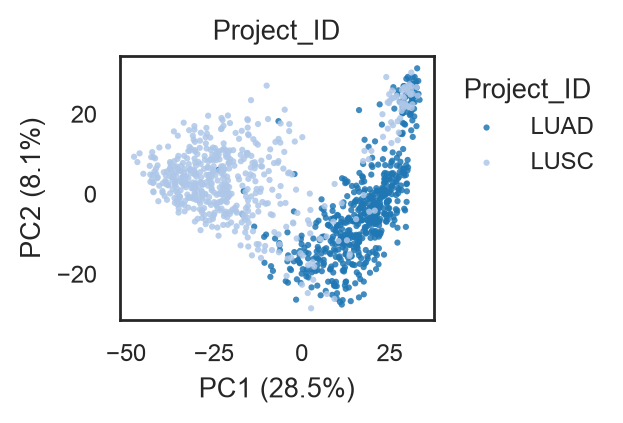

(<Figure size 600x400 with 1 Axes>,
 [<Axes: title={'center': 'Project_ID'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [32]:
bk.pl.pca_scatter(adata, color="Project_ID", palette="tab20", figsize=(3,2), point_size=5,
                 save=FIGURES + "pca_projectID.png")

# palette "tab20", "husl"...

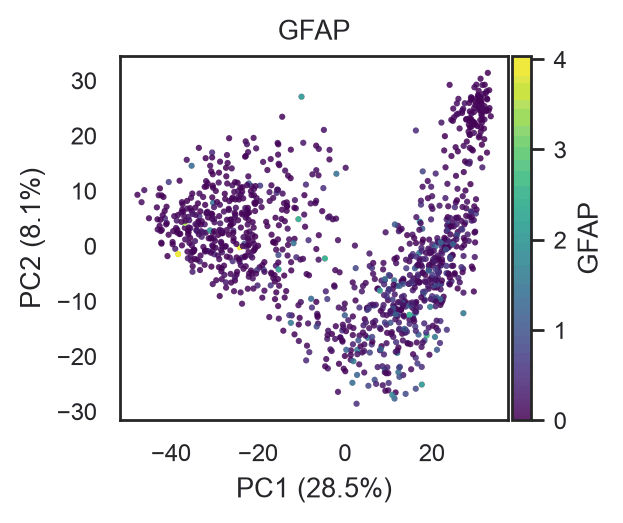

(<Figure size 600x500 with 2 Axes>,
 [<Axes: title={'center': 'GFAP'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [33]:
bk.pl.pca_scatter(adata, color="GFAP", layer="log1p_cpm", cmap="viridis", point_size=5, figsize=(3,2.5))

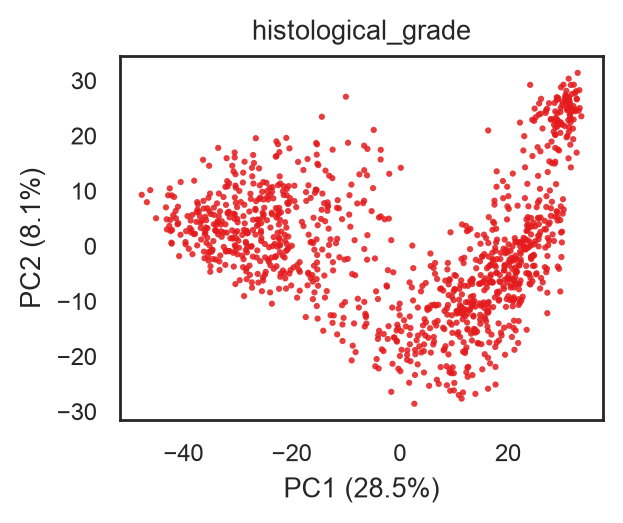

(<Figure size 600x500 with 1 Axes>,
 [<Axes: title={'center': 'histological_grade'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [34]:
bk.pl.pca_scatter(adata, color="histological_grade", point_size=5, figsize=(3,2.5))

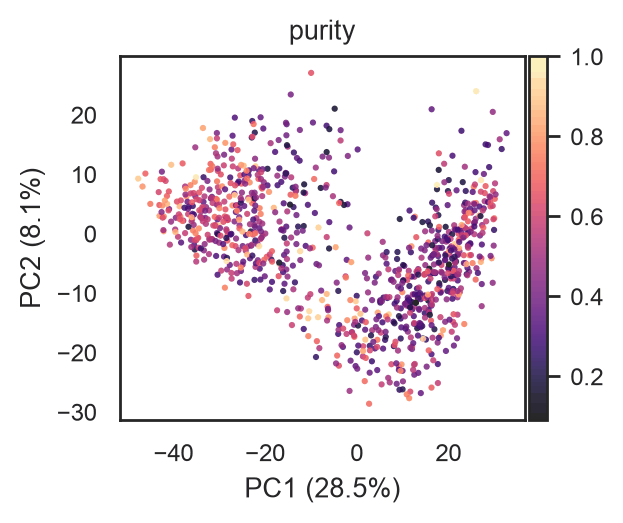

(<Figure size 600x500 with 2 Axes>,
 [<Axes: title={'center': 'purity'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>])

In [35]:
bk.pl.pca_scatter(adata, color="purity", point_size=5, figsize=(3,2.5), cmap="magma")

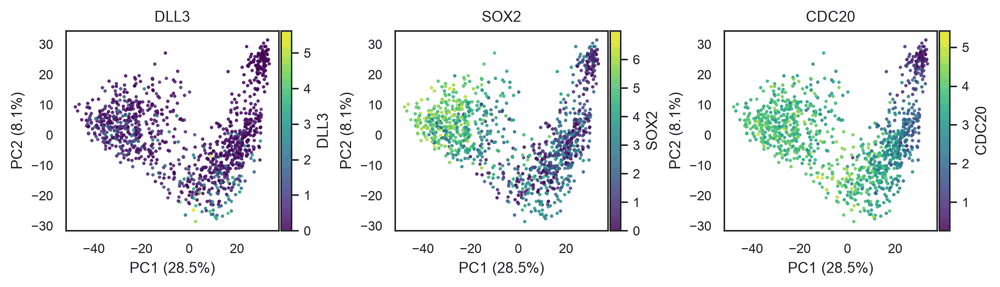

(<Figure size 1800x500 with 6 Axes>,
 array([<Axes: title={'center': 'DLL3'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'SOX2'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>,
        <Axes: title={'center': 'CDC20'}, xlabel='PC1 (28.5%)', ylabel='PC2 (8.1%)'>],
       dtype=object))

In [36]:
bk.pl.pca_scatter(adata, color=["DLL3","SOX2","CDC20"], layer="log1p_cpm", point_size=5, 
                  figsize=(3,2.5), cmap="viridis", save=FIGURES + "pca_genes.png")

### PCA Variance

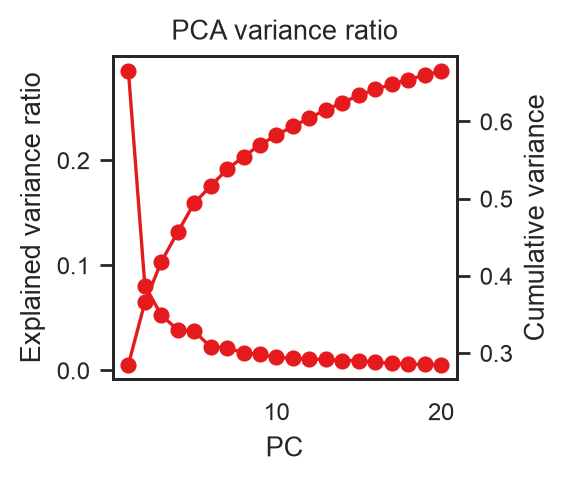

(<Figure size 600x500 with 2 Axes>,
 <Axes: title={'center': 'PCA variance ratio'}, xlabel='PC', ylabel='Explained variance ratio'>)

In [37]:
# 4) scree
bk.pl.pca_variance_ratio(adata,  figsize=(3, 2.5),
                         save= FIGURES + "pca_variance_ratio_example.png")

#If you ever call PCA with key_added="pca_hvg", then:
bk.pl.pca_variance_ratio(adata, key="pca_hvg")

## 4.2. PCA loadings

In [38]:
bk.tl.pca_loadings(adata, pcs=[1,2], n_top=5)

{'PC1_pos':         pc sign  rank    gene   loading
 6293   PC1  pos     1   NAPSA  0.085234
 12006  PC1  pos     2   SFTPC  0.082065
 12088  PC1  pos     3   SFTPB  0.081473
 5221   PC1  pos     4  SFTPA1  0.078480
 15053  PC1  pos     5  SFTPA2  0.076387,
 'PC1_neg':         pc sign  rank   gene   loading
 15228  PC1  neg     1   KRT5 -0.125829
 17337  PC1  neg     2  KRT6A -0.122231
 6789   PC1  neg     3   DSG3 -0.101465
 6793   PC1  neg     4   DSC3 -0.092037
 15378  PC1  neg     5  KRT16 -0.091448,
 'PC2_pos':         pc sign  rank    gene   loading
 12006  PC2  pos     1   SFTPC  0.154571
 5221   PC2  pos     2  SFTPA1  0.110094
 15053  PC2  pos     3  SFTPA2  0.107006
 964    PC2  pos     4  CLDN18  0.103342
 17058  PC2  pos     5    AGER  0.103332,
 'PC2_neg':         pc sign  rank       gene   loading
 12664  PC2  neg     1        FGB -0.066207
 8790   PC2  neg     2     FAM83A -0.062556
 385    PC2  neg     3    CYP24A1 -0.059598
 813    PC2  neg     4    COL11A1 -0.058464
 

In [39]:
#Export
bk.tl.pca_loadings(
    adata,
    pcs=[1,2,3,4,5],
    n_top=100,
    export=TABLES + "TCGA_pca_loadings.tsv",
    export_gmt=TABLES + "TCGA_pca_loadings.gmt",
)

{'PC1_pos':         pc sign  rank     gene   loading
 6293   PC1  pos     1    NAPSA  0.085234
 12006  PC1  pos     2    SFTPC  0.082065
 12088  PC1  pos     3    SFTPB  0.081473
 5221   PC1  pos     4   SFTPA1  0.078480
 15053  PC1  pos     5   SFTPA2  0.076387
 ...    ...  ...   ...      ...       ...
 382    PC1  pos    96    VSIG2  0.037892
 11653  PC1  pos    97   MS4A15  0.037642
 5415   PC1  pos    98   ATP8A1  0.037462
 14036  PC1  pos    99  ALOX15B  0.037456
 3271   PC1  pos   100     AGR2  0.037377
 
 [100 rows x 5 columns],
 'PC1_neg':         pc sign  rank    gene   loading
 15228  PC1  neg     1    KRT5 -0.125829
 17337  PC1  neg     2   KRT6A -0.122231
 6789   PC1  neg     3    DSG3 -0.101465
 6793   PC1  neg     4    DSC3 -0.092037
 15378  PC1  neg     5   KRT16 -0.091448
 ...    ...  ...   ...     ...       ...
 5652   PC1  neg    96  FAM83C -0.040245
 3165   PC1  neg    97    DLX5 -0.040181
 13091  PC1  neg    98    HAP1 -0.040163
 15800  PC1  neg    99    SBSN -0.040

In [40]:
#Absolute loadings only (single list per PC)
bk.tl.pca_loadings(adata, pcs=[1,2,3], n_top=100, use_abs=True)

{'PC1_abs':         pc sign  rank    gene   loading
 15228  PC1  abs     1    KRT5 -0.125829
 17337  PC1  abs     2   KRT6A -0.122231
 6789   PC1  abs     3    DSG3 -0.101465
 6793   PC1  abs     4    DSC3 -0.092037
 15378  PC1  abs     5   KRT16 -0.091448
 ...    ...  ...   ...     ...       ...
 16055  PC1  abs    96   ADH1B  0.049876
 1056   PC1  abs    97  ADGRF5  0.049845
 15089  PC1  abs    98    MUC1  0.049840
 12662  PC1  abs    99     FGG  0.049745
 11935  PC1  abs   100  FAM83B -0.049734
 
 [100 rows x 5 columns],
 'PC2_abs':         pc sign  rank    gene   loading
 12006  PC2  abs     1   SFTPC  0.154571
 5221   PC2  abs     2  SFTPA1  0.110094
 15053  PC2  abs     3  SFTPA2  0.107006
 964    PC2  abs     4  CLDN18  0.103342
 17058  PC2  abs     5    AGER  0.103332
 ...    ...  ...   ...     ...       ...
 11107  PC2  abs    96   FABP5  0.049911
 12004  PC2  abs    97    TNXB  0.049790
 9984   PC2  abs    98   ITLN2  0.049733
 10570  PC2  abs    99    PIGR  0.049514
 11885  

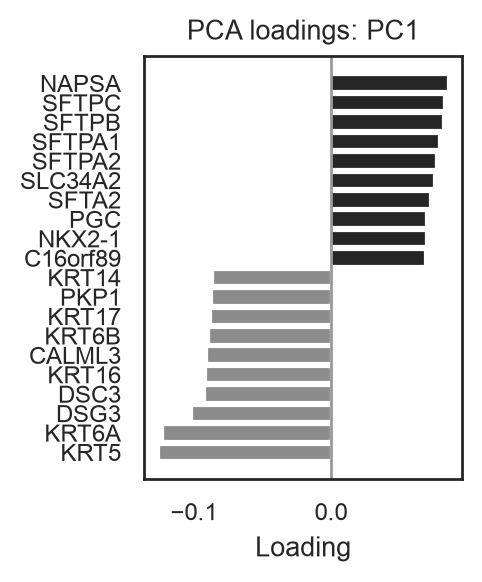

(<Figure size 500x600 with 1 Axes>,
 <Axes: title={'center': 'PCA loadings: PC1'}, xlabel='Loading'>)

In [41]:
# Barplot for PC1 (top pos/neg)
bk.pl.pca_loadings_bar(adata, pc=1, n_top=10, figsize=(2.5,3),
                      save=FIGURES + "pc1_loadings_bar.png")

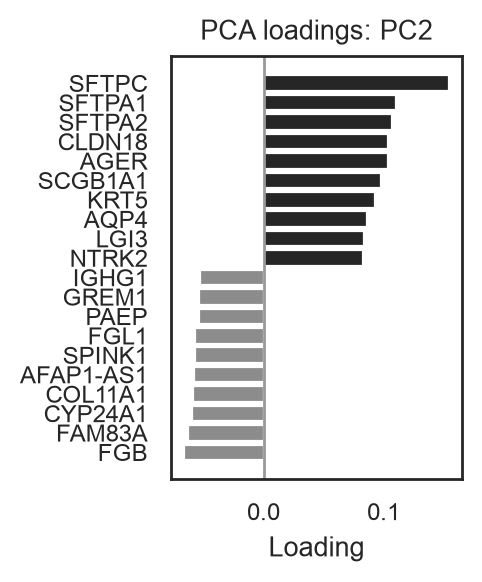

(<Figure size 500x600 with 1 Axes>,
 <Axes: title={'center': 'PCA loadings: PC2'}, xlabel='Loading'>)

In [42]:
# Barplot for PC2 (top pos/neg)
bk.pl.pca_loadings_bar(adata, pc=2, n_top=10, figsize=(2.5,3),
                      save=FIGURES + "pc2_loadings_bar.png")

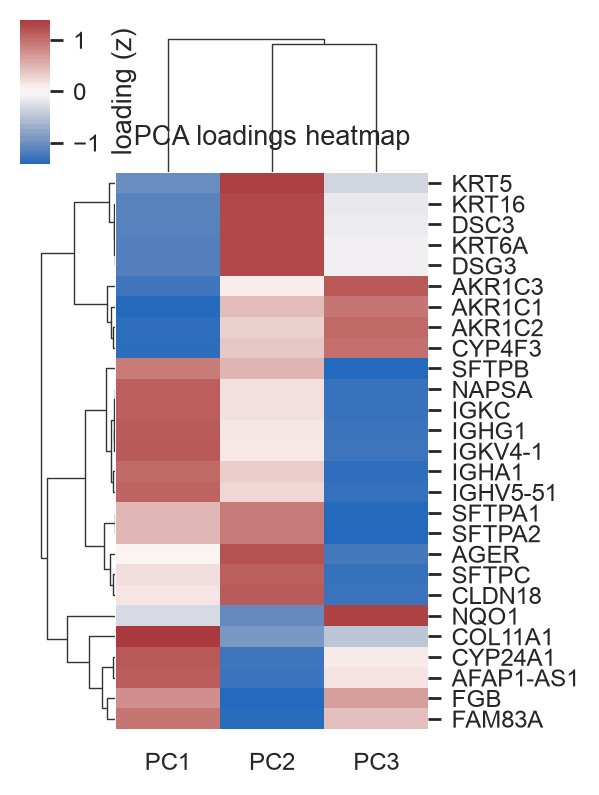

In [43]:
# Heatmap for PC1–PC5 (union of top genes)
bk.pl.pca_loadings_heatmap(
    adata,
    pcs=[1,2,3],
    n_top=5,
    cluster_genes=True,
    cluster_pcs=True,
    z_score=True,
    figsize=(3,4),
    save=FIGURES + "pca_loadings_heatmap_TCGAall.png",
);

## 4.3. Neighbors & UMAP

Common bulk-friendly parameter ranges
	•	n_neighbors: 10–30 (for ~100 samples, 15 is a good start)
	•	resolution:
	•	0.3–0.8 for broader groups
	•	1.0–2.0 for finer subclusters

In [44]:
# Calculate neighbors - PCA should be already computed
bk.tl.neighbors(adata, n_neighbors=15, n_pcs=20, metric="euclidean")

In [45]:
bk.tl.umap(adata, n_neighbors=8, n_pcs=30, min_dist=0.3, random_state=0)    #0.3

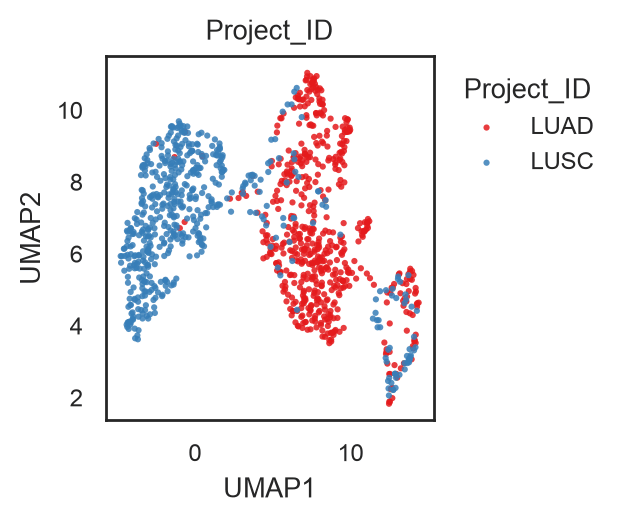

(<Figure size 600x500 with 1 Axes>,
 [<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [46]:
bk.pl.umap(adata, color="Project_ID", 
           figsize=(3,2.5),
           point_size=5,    # palette "husl".. others
           save=FIGURES + "UMAP_ProjectID.png")

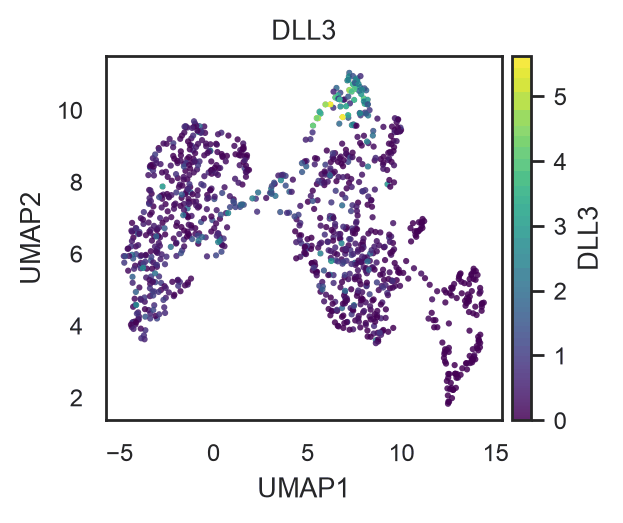

(<Figure size 600x500 with 2 Axes>,
 [<Axes: title={'center': 'DLL3'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [47]:
# gene expression (continuous, from a layer)
bk.pl.umap(adata, color="DLL3", layer="log1p_cpm", figsize=(3,2.5), point_size=5,
          save=FIGURES + "UMAP_DLL3.png")   #cmap="magma"

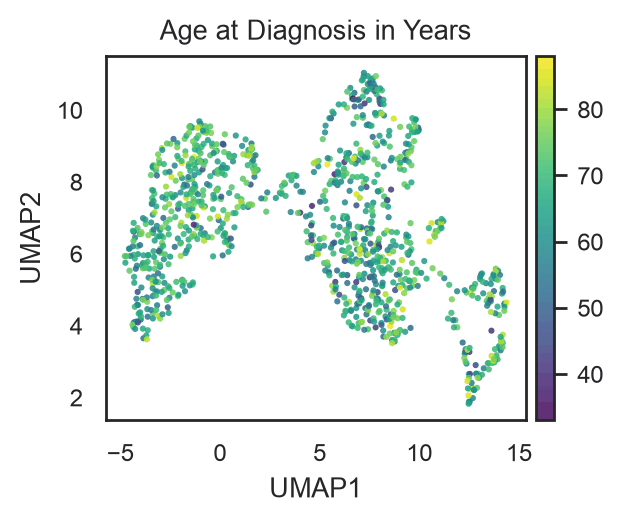

(<Figure size 600x500 with 2 Axes>,
 [<Axes: title={'center': 'Age at Diagnosis in Years'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [48]:
# continuous metadata
bk.pl.umap(adata, color="Age at Diagnosis in Years", 
           figsize=(3,2.5), point_size=5, 
           cmap="viridis")


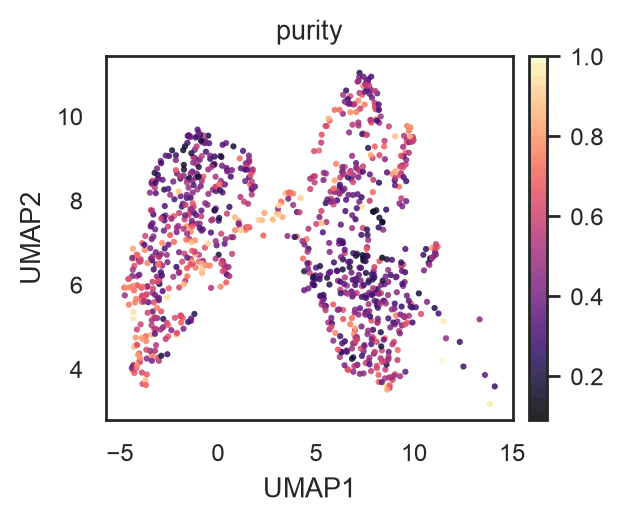

(<Figure size 600x500 with 2 Axes>,
 [<Axes: title={'center': 'purity'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [49]:
# continuous metadata
bk.pl.umap(adata, color="purity", 
           figsize=(3,2.5), point_size=5, 
           cmap="magma",
          save=FIGURES + "UMAP_purity_magma.png")

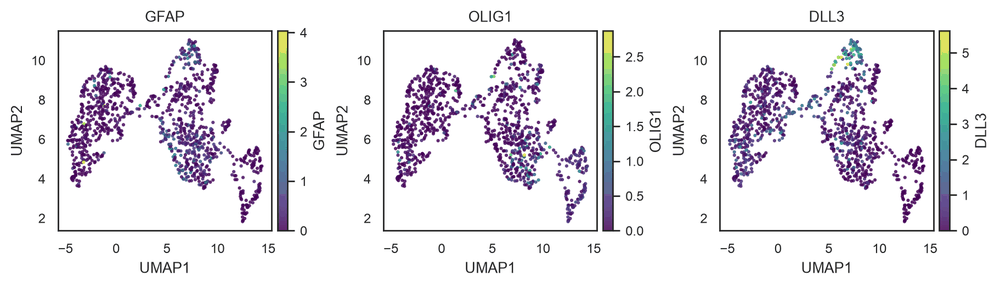

(<Figure size 1800x500 with 6 Axes>,
 array([<Axes: title={'center': 'GFAP'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'OLIG1'}, xlabel='UMAP1', ylabel='UMAP2'>,
        <Axes: title={'center': 'DLL3'}, xlabel='UMAP1', ylabel='UMAP2'>],
       dtype=object))

In [50]:
# multiple genes → 1 row of panels
bk.pl.umap(adata, color=["GFAP", "OLIG1", "DLL3"], layer="log1p_cpm", 
           figsize=(3,2.5),
           point_size=5, cmap="viridis",
          save=FIGURES + "umap_genes_example.png")

### Compare umap & umap_graph:  
- umap: regular, representation-driven, standard
- umap_graph: “Graph-enforced UMAP reveals subtype separation”, topology-preserving, exploratory

Original:  
- min_dist=0.3,
- random_state=0,

In [51]:
bk.tl.umap_graph(
    adata,
    graph_key="connectivities",
    min_dist=0.5,
    random_state=0,
)

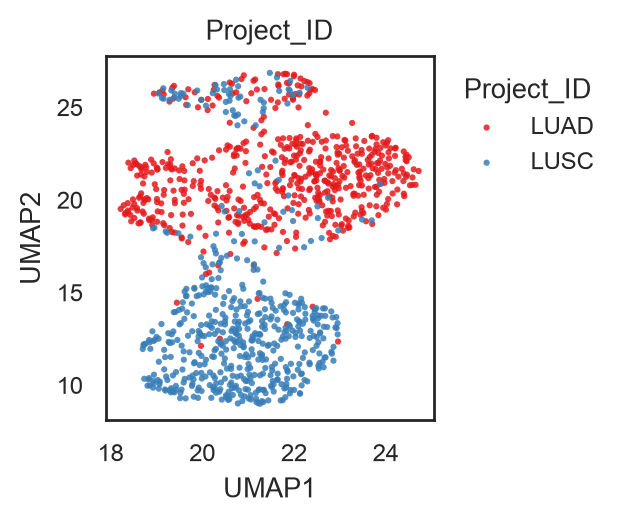

(<Figure size 600x500 with 1 Axes>,
 [<Axes: title={'center': 'Project_ID'}, xlabel='UMAP1', ylabel='UMAP2'>])

In [52]:
bk.pl.umap(adata, basis="X_umap_graph", color="Project_ID", figsize=(3,2.5), 
           point_size=5) 

#### Save bidimensional representation X,Y values

In [53]:
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")

# 5. Utilities
<a id="utilities"></a>

## 5.1. Pandas for manipulating expression data and metadata

Set Sample ID as index using pandas and transpose the table

## 5.2 Sanitize metadata

OPTIONAL.   
It is important that metadata columns are in the proper dtype (categories, numeric, text, etc.) for downstream studies. IF you get problems later with your metadata you can use this utilite below

Check observations

In [54]:
bad, _ = bk.pp.find_bad_obs_cols_by_write(adata, n_rows=3000)
print("bad before:", len(bad), bad[:10])
print(" --------------------- ")

adata_safe, rep = bk.pp.make_obs_h5ad_safe_strict(adata, copy=True)
print(rep)
print(" --------------------- ")

bad2, _ = bk.pp.find_bad_obs_cols_by_write(adata_safe, n_rows=3000)
print("bad after (2nd):", len(bad2), bad2[:10])

bad before: 0 []
 --------------------- 
{'numeric_coerced': [], 'string_to_object': ['Sample_ID', 'sample.1', 'samples.sample_id'], 'stringified': ['Sample_ID', 'sample.1', 'samples.sample_id'], 'category_fixed': ['Patient_ID', 'Project_ID', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'histological_type', 'vital_status', 'tumor_status', 'new_tumor_event_type', 'treatment_outcome_first_course', 'Subtype_mRNA', 'Subtype_DNAmeth', 'Subtype_Selected', 'sample_type', '_primary_disease', 'Subtype_Immune_Model_Based', 'Aneu', 'WAneu', 'program', 'project_id_TCGA', 'Gender', '_PATIENT', 'demographic.demographic_id', 'demographic.ethnicity', 'demographic.gender', 'demographic.race', 'demographic.submitter_id', 'demographic.updated_datetime', 'demographic.vital_status', 'diagnoses.diagnosis_id', 'diagnoses.icd_10_code', 'diagnoses.morphology', 'diagnoses.primary_diagnosis', 'diagnoses.prior_malignancy', 'diagnoses.prior_treatment', 'diagnoses.site_of_resection_or_biopsy', 'diagnoses.submit

Check var

In [55]:
adata_safe.var_names_make_unique()  # recommended

_, rep_var = bk.pp.make_var_h5ad_safe_strict(adata_safe, copy=False)
print(rep_var)

# re-test var
bad_var2, _ = bk.pp.find_bad_var_cols_by_write(adata_safe, n_cols=60000)
print("bad var after:", len(bad_var2), bad_var2[:20])

{'string_to_object': ['ensembl_id'], 'category_fixed': ['chromosome', 'gene_name', 'gene_type'], 'bytes_stringified': [], 'nonscalar_stringified': [], 'mixed_object_stringified': [], 'errors': [], 'n_cols': 10}
bad var after: 0 []


Once bad/bad var == 0:

In [56]:
adata = adata_safe.copy()

In [57]:
# HDF5 forbids '/' in keys; rename them before writing
bk.pp.make_h5ad_safe(adata)
adata.write(H5AD, compression="gzip")


## 5.3. Batch Correction

Best practice is to run ComBat on log-normalized expression (not raw counts):

In [58]:
# Select metadata column for batch effect analysis (e.g. "Batch" or "Project_ID", or "gender")
batch_col = "gender"

adata.obs[batch_col].value_counts()

gender
MALE      660
FEMALE    448
Name: count, dtype: int64

In [59]:
bk.pp.batch_correct_combat(
    adata,
    batch_key=batch_col,
    layer="log1p_cpm",
    #covariates=["Subtype_mRNA"],   # optional, preserve biology
    key_added="combat_log1p_cpm",
)

In [60]:
adata.layers

Layers with keys: None, 'counts', 'cpm', 'log1p_cpm', 'combat_log1p_cpm'

Then use downstream:   
- `bk.tl.pca(adata, layer="combat_log1p_cpm", use_highly_variable=True)`   
- `bk.tl.neighbors(adata, use_rep="X_pca", n_neighbors=15)`     
- `bk.tl.umap(adata)`    